# 02 - Exploratory data analysis

Descriptive analysis of the **resolved** modelling population (plus all statuses where noted).
Observations are associations in Lending Club's *approved* portfolio, not causal effects.
Run `python scripts/prepare_data.py` first.

> Notebooks display **aggregates only** (no individual loan records) and reuse functions from `src/creditiq/`. Educational project - not for real lending decisions.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from creditiq.config import load_config, setup_logging
from creditiq.cli import processed_path, clean_all_path
from creditiq.reporting import figures as figs

setup_logging("WARNING")
cfg = load_config()
figs.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
TARGET = cfg["target"]["name"]

In [2]:
from creditiq.analytics.duckdb_queries import connect, run_all
from creditiq.data.validate import data_quality_summary

loans = pd.read_parquet(processed_path(cfg))
loans_all = pd.read_parquet(clean_all_path(cfg))
print(f"All cleaned loans: {loans_all.shape}; resolved modelling population: {loans.shape}")
con = connect({"loans_all": clean_all_path(cfg), "loans": processed_path(cfg)})
sql = run_all(cfg.path("sql_dir"), con)

All cleaned loans: (423810, 46); resolved modelling population: (411274, 48)


## Target distribution and class imbalance

Adverse rate: 17.22%  -> imbalance ratio 4.8 : 1


,loan_status,n_loans,pct
0,Fully Paid,340444,80.33
1,Charged Off,70829,16.71
2,Current,11925,2.81
3,Late (31-120 days),337,0.08
4,In Grace Period,201,0.05
5,Late (16-30 days),73,0.02
6,Default,1,0.00


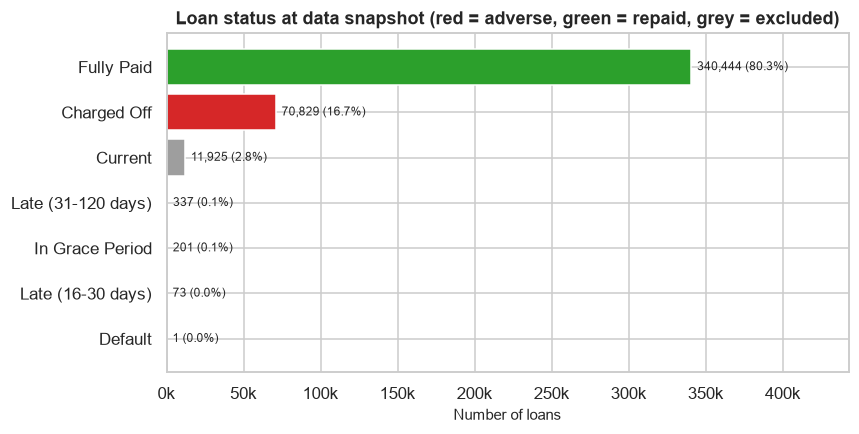

In [3]:
rate = loans[TARGET].mean()
print(f"Adverse rate: {rate:.2%}  -> imbalance ratio {(1 - rate) / rate:.1f} : 1")
display(sql["01_data_quality.status_distribution"])
from creditiq.data.target import status_summary
figs.plot_status_distribution(status_summary(loans_all, cfg["target"]));

## Missingness

,0
n,423810.00
pct_missing_emp_length,4.70
pct_missing_revol_util,0.06
pct_missing_mths_since_last_delinq,52.73
pct_missing_mths_since_last_record,86.08
pct_missing_mths_since_last_major_derog,76.64
pct_missing_earliest_cr_line,0.00


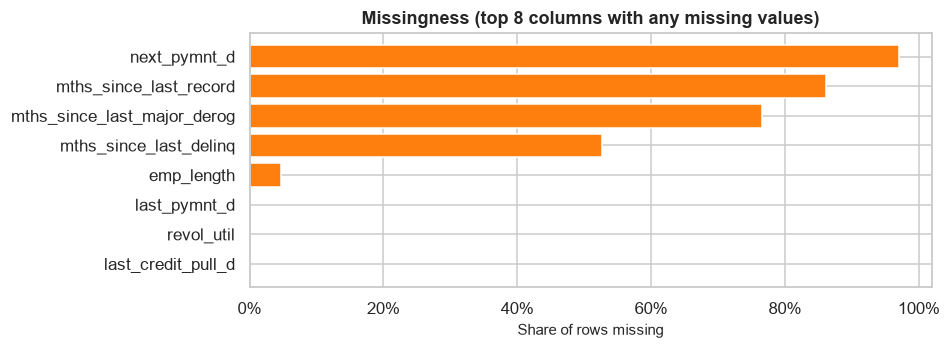

In [4]:
figs.plot_missingness(data_quality_summary(loans_all));
display(sql["01_data_quality.key_field_missingness"].T)

## Time coverage and vintage behaviour

,issue_d,n_loans,n_resolved
0,2012-01-01,2602,2602.0
1,2012-02-01,2560,2560.0
2,2012-03-01,2914,2914.0


,issue_d,n_loans,n_resolved
33,2014-10-01,38783,36072.0
34,2014-11-01,25054,22957.0
35,2014-12-01,10307,9367.0


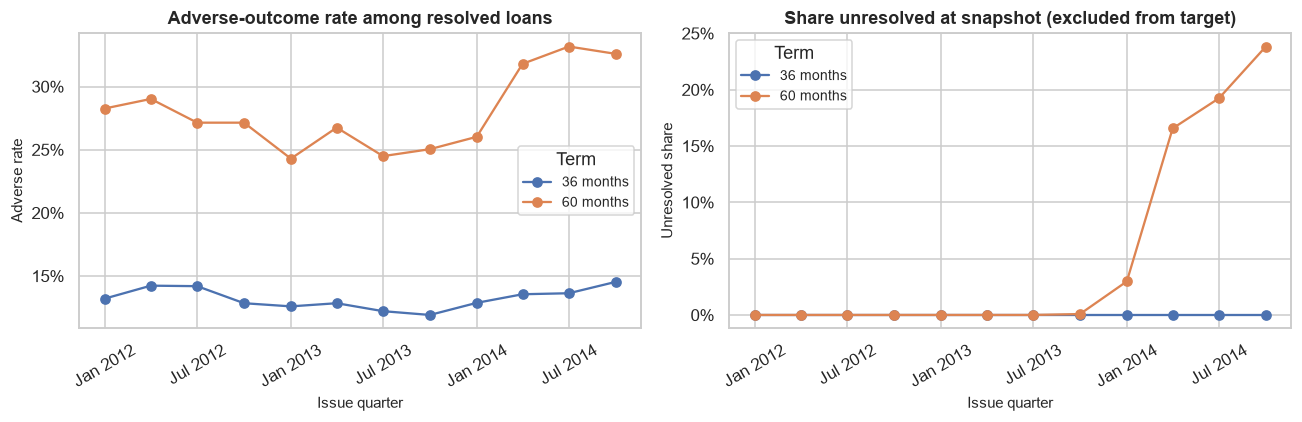

In [5]:
display(sql["01_data_quality.issue_month_coverage"].head(3)); display(sql["01_data_quality.issue_month_coverage"].tail(3))
figs.plot_vintage_rates(sql["02_portfolio_analysis.adverse_rate_by_vintage_term"],
                        sql["02_portfolio_analysis.unresolved_share_by_vintage_term"]);

## Loan amount, income, DTI and credit history by outcome

is_adverse,median_fully_paid,median_adverse
loan_amnt,12000.000,14400.000
annual_inc,65000.000,59400.000
dti,16.780,19.030
revol_util,0.573,0.611
revol_bal,11942.000,11751.500
open_acc,10.000,11.000
total_acc,24.000,23.000


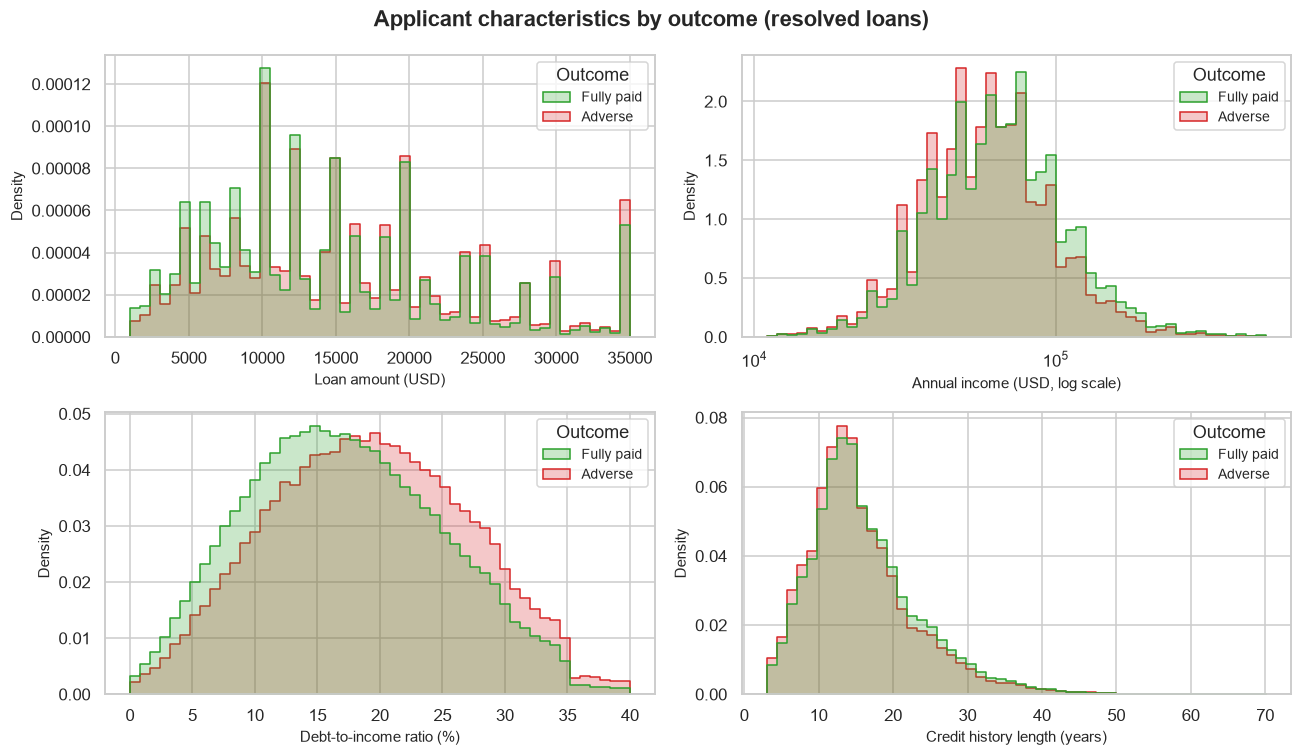

In [6]:
figs.plot_numeric_distributions(loans, TARGET);
cols = ["loan_amnt", "annual_inc", "dti", "revol_util", "revol_bal", "open_acc", "total_acc"]
display(loans.groupby(TARGET)[cols].median().T.rename(columns={0: "median_fully_paid", 1: "median_adverse"}))

## Employment, purpose, home ownership, income band

In [7]:
display(sql["02_portfolio_analysis.adverse_rate_by_purpose"])
display(sql["02_portfolio_analysis.adverse_rate_by_home_ownership"])
display(sql["02_portfolio_analysis.adverse_rate_by_income_band"])
emp = loans.assign(emp_length=loans["emp_length"].astype("string").fillna("Missing")).groupby("emp_length", observed=True)[TARGET].agg(["mean", "size"])
display(emp.rename(columns={"mean": "adverse_rate", "size": "n_loans"}))

,purpose,n_loans,adverse_rate,volume_musd
0,debt_consolidation,246504,0.1823,3740.48
1,credit_card,95722,0.1444,1410.86
2,home_improvement,22603,0.1548,318.58
3,other,18880,0.1904,183.81
4,major_purchase,7346,0.1518,81.19
5,small_business,4921,0.2640,78.13
6,medical,3785,0.1855,33.55
7,car,3719,0.1248,31.96
8,moving,2327,0.2089,17.88
9,vacation,2070,0.1676,12.69


,home_ownership,n_loans,adverse_rate
0,MORTGAGE,209623,0.1548
1,RENT,164276,0.1935
2,OWN,37286,0.1764
3,OTHER,89,0.1798


,income_band,n_loans,adverse_rate,median_dti
0,1: < 40k,65381,0.2059,19.59
1,2: 40k-60k,114955,0.1918,18.89
2,3: 60k-80k,94889,0.1735,17.45
3,4: 80k-120k,90620,0.1452,15.77
4,5: >= 120k,45429,0.1256,12.74


,adverse_rate,n_loans
emp_length,,
1 year,0.168277,25357
10+ years,0.165821,135628
2 years,0.166779,35658
3 years,0.168691,31365
4 years,0.167988,23710
5 years,0.166429,26666
6 years,0.175910,23171
7 years,0.174755,23656
8 years,0.177085,20205


## Grade and interest rate (origination-time information; not used by the applicant model)

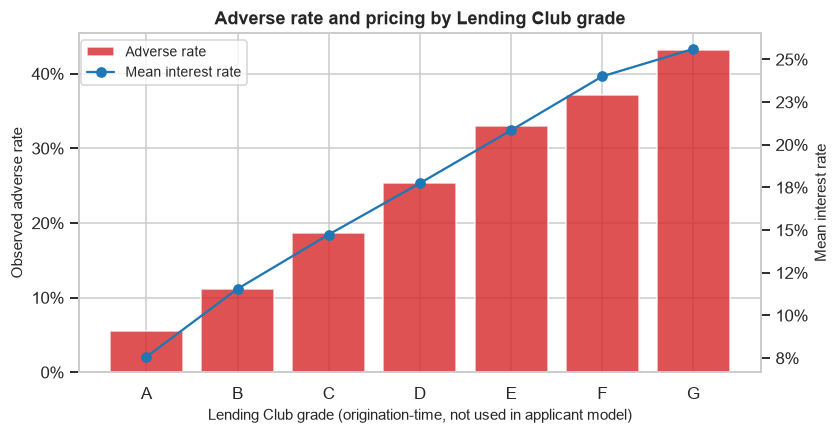

In [8]:
figs.plot_grade_analysis(sql["02_portfolio_analysis.adverse_rate_by_grade"]);

## Outliers

In [9]:
num = ["loan_amnt", "annual_inc", "dti", "revol_bal", "revol_util", "open_acc", "total_acc", "delinq_2yrs", "pub_rec"]
q = loans[num].quantile([0.001, 0.01, 0.5, 0.99, 0.999]).T
q["max"] = loans[num].max()
q["n_above_p99.9"] = [(loans[c] > loans[c].quantile(0.999)).sum() for c in num]
display(q)
display(sql["01_data_quality.range_checks"].T)

,0.001,0.01,0.5,0.99,0.999,max,n_above_p99.9
loan_amnt,1000.00,1925.000,12375.00,35000.000,35000.000,35000.000,0
annual_inc,11000.00,19200.000,63000.00,241000.000,500000.000,7500000.000,361
dti,0.37,2.100,17.16,34.720,39.210,39.990,408
revol_bal,0.00,477.000,11906.00,80924.430,231744.587,2568995.000,412
revol_util,0.00,0.034,0.58,0.978,1.020,1.803,408
open_acc,2.00,3.000,11.00,27.000,37.000,84.000,340
total_acc,4.00,6.000,24.00,60.000,72.000,156.000,409
delinq_2yrs,0.00,0.000,0.00,4.000,8.000,29.000,306
pub_rec,0.00,0.000,0.00,2.000,5.000,63.000,268


,0
non_positive_loan_amnt,0.0
non_positive_annual_inc,0.0
dti_out_of_range,0.0
revol_util_out_of_range,0.0
int_rate_out_of_range,0.0
open_exceeds_total_acc,0.0
credit_line_after_issue,0.0
funded_differs_from_requested,65.0


Extreme values (e.g. very high incomes and revolving balances) are kept: they are plausible
self-reported values. Tree models are insensitive to them; the logistic regression winsorises
at quantiles learned on the training split only.

## Correlation of engineered numeric features (training split)

,,abs_spearman
pub_rec,has_public_record,0.999609
delinq_2yrs,mths_since_last_delinq,0.825460
log_revol_bal,revol_bal_to_income,0.767964
mths_since_last_delinq,mths_since_last_major_derog,0.731404
open_acc,total_acc,0.664077
loan_amnt,loan_to_income,0.619544
delinq_2yrs,mths_since_last_major_derog,0.571092
has_delinq_history,has_major_derog,0.521376


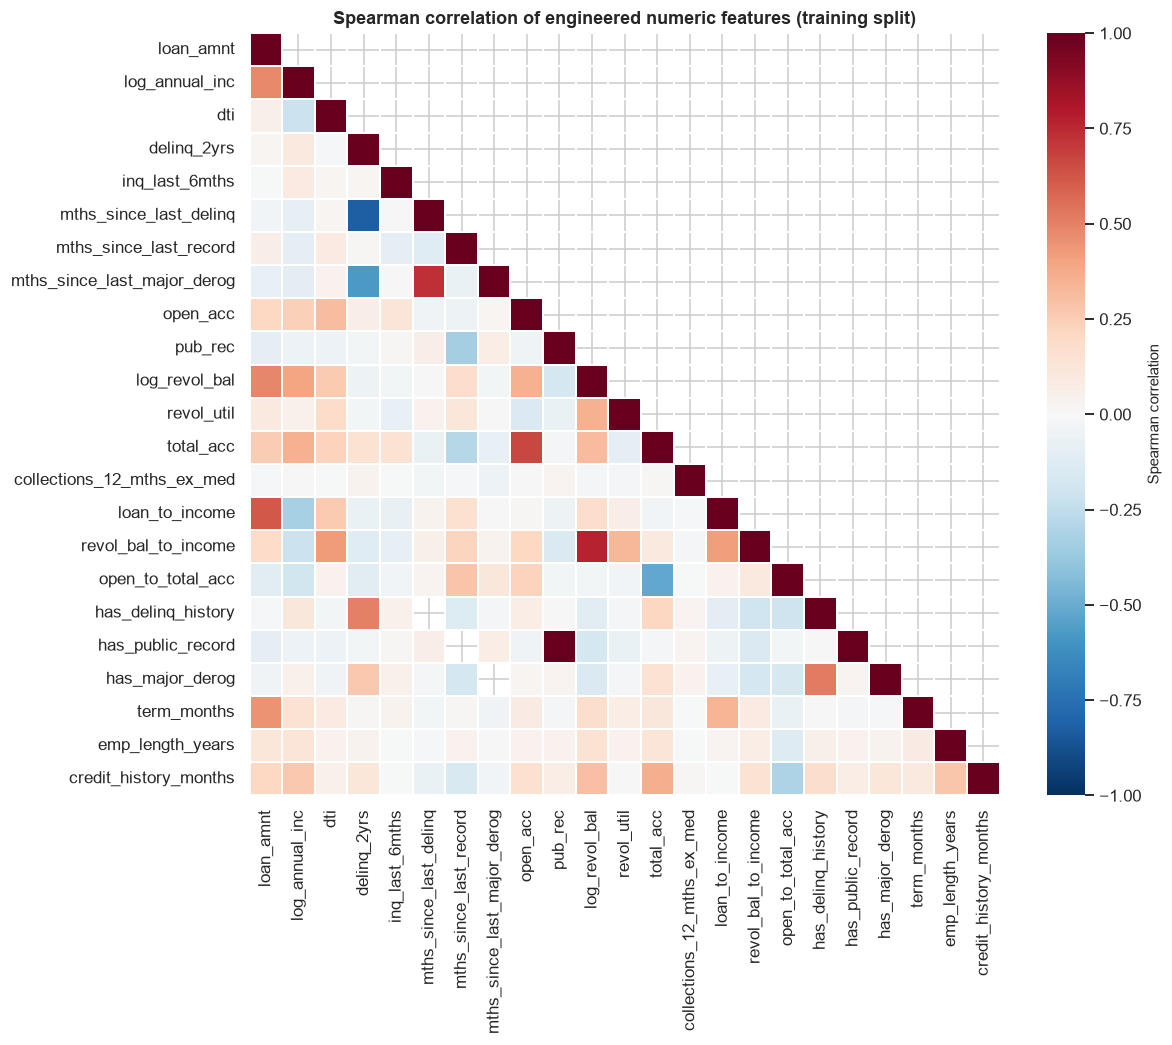

In [10]:
from creditiq.features.build_features import resolve_feature_spec, engineer_features, engineered_column_groups
spec = resolve_feature_spec(cfg.raw, "applicant")
train = loans[loans["split"].astype(str) == "train"]
nums, _ = engineered_column_groups(spec)
feats = engineer_features(train.sample(50000, random_state=cfg.seed), spec)[nums]
figs.plot_correlation(feats);
corr = feats.corr(method="spearman").abs().where(lambda d: np.triu(np.ones(d.shape, bool), 1)).stack().sort_values(ascending=False)
display(corr.head(8).rename("abs_spearman").to_frame())